# LAB 13 — Artificial Neural Networks: The Multi-Layer Perceptron
## Student Information
- **Name:** Muhammad Anees  
- **Roll No:** 023-24-0251
- **Section:** H 
- **Date:** 24-11-2026

**Dataset:** XOR and Breast Cancer Wisconsin (sklearn built-in)

In [3]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)
X_xor = np.array([[0,0],[0,1],[1,0],[1,1]])
y_xor = np.array([0, 1, 1, 0])
print("Ready. TensorFlow", tf.__version__)


Ready. TensorFlow 2.22.0-rc1


## Part 0 — Key Concepts
Read the definitions table in the lab manual before starting.

## Part 1 — Why We Need Non-Linear Activations

### 1.1 Activation Functions and Their Slopes
**Task 1.1** — Plot the step and sigmoid functions and their derivatives (2×2 grid). Print each maximum derivative.

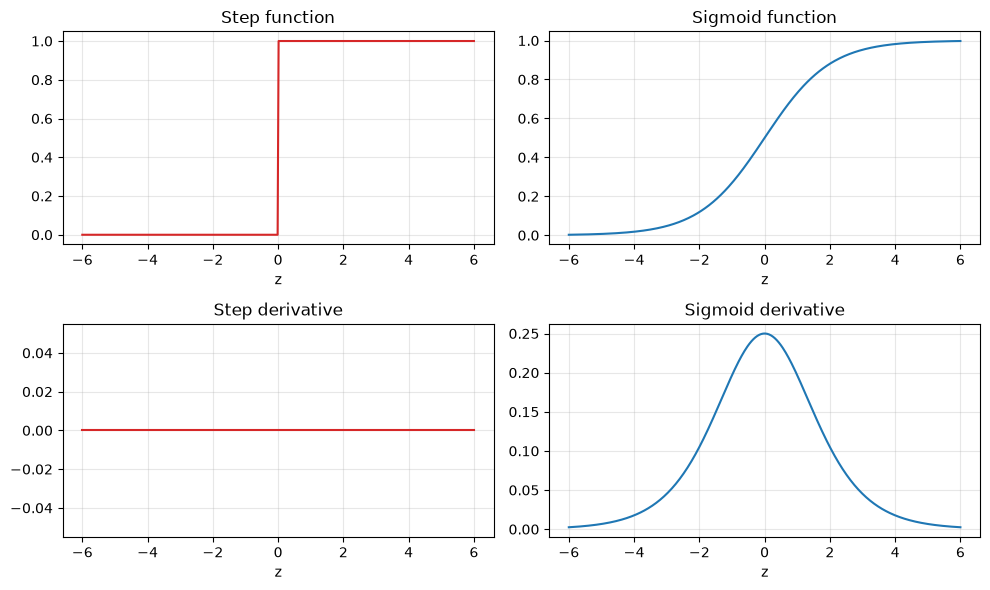

Max derivative of step    : 0.0
Max derivative of sigmoid : 0.25


In [4]:
# Task 1.1
def step(z):
    return np.where(z >= 0, 1.0, 0.0)

def step_deriv(z):
    # slope of a flat staircase is 0 everywhere (the jump at z=0 is ignored)
    return np.zeros_like(z)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_deriv(z):
    s = sigmoid(z)
    return s * (1 - s)

z = np.linspace(-6, 6, 400)

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes[0, 0].plot(z, step(z), color="tab:red")
axes[0, 0].set_title("Step function")
axes[0, 1].plot(z, sigmoid(z), color="tab:blue")
axes[0, 1].set_title("Sigmoid function")
axes[1, 0].plot(z, step_deriv(z), color="tab:red")
axes[1, 0].set_title("Step derivative")
axes[1, 1].plot(z, sigmoid_deriv(z), color="tab:blue")
axes[1, 1].set_title("Sigmoid derivative")
for ax in axes.ravel():
    ax.set_xlabel("z")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Max derivative of step    :", step_deriv(z).max())
print("Max derivative of sigmoid :", round(sigmoid_deriv(z).max(), 4))


**Interpretation:** The step function is just two flat lines with a jump at z = 0, so its derivative is 0 everywhere (max derivative printed = 0.0). The sigmoid is a smooth S-curve and its slope is non-zero for almost every z, with a peak of 0.25 at z = 0 (printed max = 0.25). The slope fades away when |z| is large (beyond about ±5) because the curve flattens out there.

**Why can the step function not be trained with gradient descent?** Gradient descent updates w ← w − η · ∂L/∂w, and since the step function's slope is 0 everywhere, the gradient is 0 and the weights never change, so nothing is learned.

### 1.2 Stacking Linear Layers Collapses
**Task 1.2** — Show that two linear layers equal one. Then add a sigmoid after the first layer and check again.

In [5]:
# Task 1.2
np.random.seed(42)
W1 = np.random.randn(2, 3)
b1 = np.random.randn(3)
W2 = np.random.randn(3, 1)
b2 = np.random.randn(1)
X = np.random.randn(5, 2)

# two linear layers
two_layer = (X @ W1 + b1) @ W2 + b2

# one merged linear layer
W = W1 @ W2
b = b1 @ W2 + b2
one_layer = X @ W + b

print("W (merged) shape:", W.shape, " b (merged):", b)
print("Linear + linear  -> allclose:", np.allclose(two_layer, one_layer))

# now put a sigmoid after the first layer
two_layer_sig = sigmoid(X @ W1 + b1) @ W2 + b2
print("Sigmoid in between -> allclose:", np.allclose(two_layer_sig, one_layer))
print()
print("Two-layer (with sigmoid):", two_layer_sig.ravel().round(4))
print("One-layer               :", one_layer.ravel().round(4))


W (merged) shape: (2, 1)  b (merged): [0.9617854]
Linear + linear  -> allclose: True
Sigmoid in between -> allclose: False

Two-layer (with sigmoid): [-0.167  -0.0311  0.001   0.3898  0.2114]
One-layer               : [-0.8999 -0.1134  0.0239  2.4467  1.0251]


**Interpretation:** With no activation, the two-layer output and the merged one-layer output (W = W1 @ W2, b = b1 @ W2 + b2) matched and `np.allclose` printed **True**. So the second layer added no extra power; the whole thing is still one linear model.

After putting a sigmoid after the first layer, `np.allclose` printed **False**. For example the two-layer outputs were [-0.167, -0.031, 0.001, 0.390, 0.211] while the one-layer outputs were [-0.900, -0.113, 0.024, 2.447, 1.025]. The sigmoid bends the data in between the layers, so it can no longer be rewritten as a single W and b. This is why depth only helps when there is a non-linear activation.

## Part 2 — Forward Pass: An MLP Solves XOR

### 2.1 Forward Pass Function
**Task 2.1** — Write `forward`. Use the step function with W1=[[1,1],[1,1]], b1=[−0.5,−1.5], W2=[[1],[−2]], b2=[−0.5]. Print the XOR table.

In [6]:
# Task 2.1
def forward(X, W1, b1, W2, b2, f):
    h = f(X @ W1 + b1)          # hidden layer
    y_hat = f(h @ W2 + b2)      # output layer
    return h, y_hat

W1_x = np.array([[1, 1], [1, 1]])
b1_x = np.array([-0.5, -1.5])
W2_x = np.array([[1], [-2]])
b2_x = np.array([-0.5])

h, y_hat = forward(X_xor, W1_x, b1_x, W2_x, b2_x, step)

print(" x1  x2 |  h1  h2 | y_hat | true y")
print("-" * 36)
for i in range(4):
    print(f" {X_xor[i,0]}   {X_xor[i,1]}  |  {int(h[i,0])}   {int(h[i,1])}  |   {int(y_hat[i,0])}   |   {y_xor[i]}")
print("\nAll four correct?", np.array_equal(y_hat.ravel().astype(int), y_xor))


 x1  x2 |  h1  h2 | y_hat | true y
------------------------------------
 0   0  |  0   0  |   0   |   0
 0   1  |  1   0  |   1   |   1
 1   0  |  1   0  |   1   |   1
 1   1  |  1   1  |   0   |   0

All four correct? True


**Interpretation:** The forward function with the step activation and the given weights gave ŷ = 0, 1, 1, 0 for the four rows, which is exactly the true XOR column (all four correct).

- **h₁ is the OR gate:** it is 0 only for (0,0) and 1 for the other three inputs.
- **h₂ is the AND gate:** it is 1 only for (1,1).

The output neuron computes h₁ − 2·h₂ − 0.5, which means "OR but not AND", and that is XOR.

### 2.2 The Hidden Layer Changes the Space
**Task 2.2** — Plot XOR in input space and in hidden space. Draw the line h₁ − 2h₂ − 0.5 = 0.

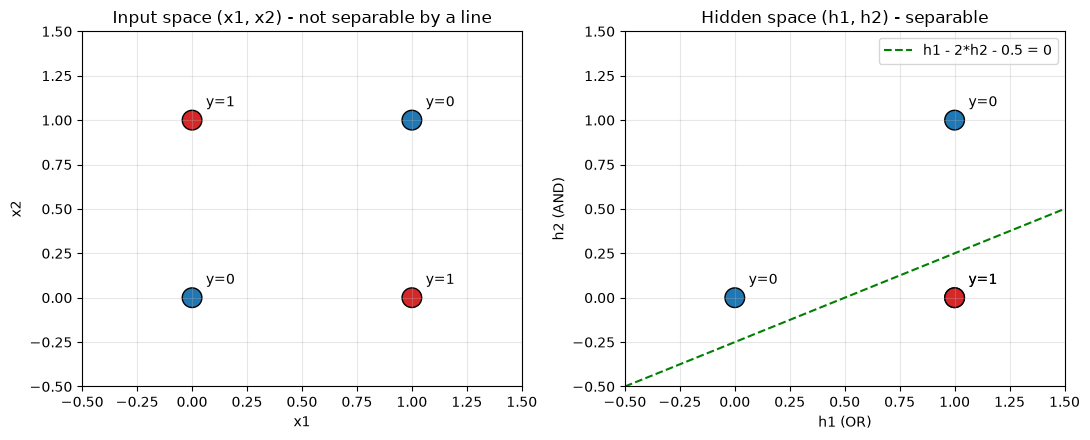

Hidden-space coordinates of the four points:
[[0 0]
 [1 0]
 [1 0]
 [1 1]]


In [7]:
# Task 2.2
colors = ["tab:blue" if c == 0 else "tab:red" for c in y_xor]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# left: input space
axes[0].scatter(X_xor[:, 0], X_xor[:, 1], c=colors, s=200, edgecolors="k")
for (a, b_), c in zip(X_xor, y_xor):
    axes[0].annotate(f"y={c}", (a, b_), textcoords="offset points", xytext=(10, 10))
axes[0].set_title("Input space (x1, x2) - not separable by a line")
axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2")
axes[0].set_xlim(-0.5, 1.5); axes[0].set_ylim(-0.5, 1.5)
axes[0].grid(alpha=0.3)

# right: hidden space
axes[1].scatter(h[:, 0], h[:, 1], c=colors, s=200, edgecolors="k")
for (a, b_), c in zip(h, y_xor):
    axes[1].annotate(f"y={c}", (a, b_), textcoords="offset points", xytext=(10, 10))
h1_line = np.linspace(-0.5, 1.5, 50)
h2_line = (h1_line - 0.5) / 2          # from h1 - 2*h2 - 0.5 = 0
axes[1].plot(h1_line, h2_line, "g--", label="h1 - 2*h2 - 0.5 = 0")
axes[1].set_title("Hidden space (h1, h2) - separable")
axes[1].set_xlabel("h1 (OR)"); axes[1].set_ylabel("h2 (AND)")
axes[1].set_xlim(-0.5, 1.5); axes[1].set_ylim(-0.5, 1.5)
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
print("Hidden-space coordinates of the four points:")
print(h.astype(int))


**Interpretation:** In the left plot (input space) the two blue points (0,0) and (1,1) sit on one diagonal and the two red points (0,1) and (1,0) on the other, so no single straight line can split them. In the right plot (hidden space) the points move to (0,0), (1,0) and (1,1), where both red points land on the same spot (1,0).

One straight line can now separate the classes because the hidden layer rearranged the points so that class 1 sits at (1,0) while class 0 sits at (0,0) and (1,1). The dashed line h₁ − 2h₂ − 0.5 = 0 passes between them, with (1,0) on one side and the other two on the other side. So the hidden layer changed the space and made the problem linearly separable.

## Part 3 — Gradient Descent and the Learning Rate

**Task 3.1** — Minimise L(w)=(w−3)² from w=−4 for 30 steps with η = 0.01, 0.1, 0.9, 1.05. Plot w vs step.

eta = 0.01  final w =        -0.8184   final loss = 1.4580e+01
eta = 0.1   final w =         2.9913   final loss = 7.5092e-05
eta = 0.9   final w =         2.9913   final loss = 7.5092e-05
eta = 1.05  final w =      -119.1458   final loss = 1.4920e+04


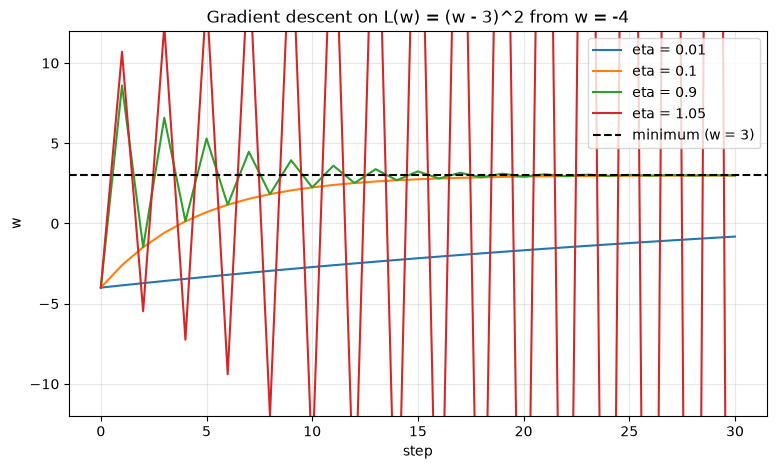


First step with eta = 0.1: -2.6 (manual: -2.6)


In [8]:
# Task 3.1
def gradient_descent(w0, eta, steps):
    w = w0
    history = [w]
    for _ in range(steps):
        grad = 2 * (w - 3)
        w = w - eta * grad
        history.append(w)
    return history

def loss(w):
    return (w - 3) ** 2

etas = [0.01, 0.1, 0.9, 1.05]
plt.figure(figsize=(9, 5))
for eta in etas:
    path = gradient_descent(-4, eta, 30)
    plt.plot(path, label=f"eta = {eta}")
    print(f"eta = {eta:<5} final w = {path[-1]:>14.4f}   final loss = {loss(path[-1]):.4e}")

plt.axhline(3, color="k", linestyle="--", label="minimum (w = 3)")
plt.ylim(-12, 12)
plt.xlabel("step"); plt.ylabel("w")
plt.title("Gradient descent on L(w) = (w - 3)^2 from w = -4")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

print("\nFirst step with eta = 0.1:", round(gradient_descent(-4, 0.1, 1)[1], 4), "(manual: -2.6)")


**Interpretation:** Starting at w = −4 and running 30 steps, the final values were:

| η | final w | final loss | behaviour |
|---|---------|-----------|-----------|
| 0.01 | −0.8184 | 14.58 | **too slow** - after 30 steps it is still far from 3 |
| 0.1 | 2.9913 | 7.5e-05 | **good** - smooth and steady move to the minimum |
| 0.9 | 2.9913 | 7.5e-05 | **zig-zags** - jumps from one side of w = 3 to the other, but the jumps shrink so it still converges |
| 1.05 | −119.15 | 14,920 | **blows up** - each jump is bigger than the last |

The update is w − 3 → (1 − 2η)(w − 3), so the distance to the minimum is multiplied by (1 − 2η) each step. For η = 0.9 that factor is −0.8, so the sign flips each step (zig-zag) but the size shrinks. For η = 1.05 the factor is −1.1, so the distance grows by 10% every step and the loss explodes. (η = 0.1 and η = 0.9 end at the same w only because 1 − 0.2 = 0.8 and |1 − 1.8| = 0.8.)

## Part 4 — Backpropagation and the Chain Rule

### 4.1 Chain Rule for One Neuron
**Task 4.1** — x=[1,2], w=[0.5,−0.3], b=0.1, y=1. Chain-rule gradient, numerical check, one update with η=0.5.

In [9]:
# Task 4.1
x = np.array([1.0, 2.0])
w = np.array([0.5, -0.3])
b = 0.1
y = 1.0

def neuron_loss(w, b):
    z = w @ x + b
    a = sigmoid(z)
    return 0.5 * (y - a) ** 2

z = w @ x + b
a = sigmoid(z)
L = 0.5 * (y - a) ** 2
print(f"z = {z:.4f}, a = {a:.4f}, L = {L:.4f}")

# chain rule
delta = -(y - a) * a * (1 - a)
dw = delta * x
db = delta
print("\nChain-rule  dL/dw =", dw.round(6), " dL/db =", round(db, 6))

# numerical check
eps = 0.0001
num_dw = np.zeros(2)
for i in range(2):
    wp = w.copy(); wm = w.copy()
    wp[i] += eps; wm[i] -= eps
    num_dw[i] = (neuron_loss(wp, b) - neuron_loss(wm, b)) / (2 * eps)
num_db = (neuron_loss(w, b + eps) - neuron_loss(w, b - eps)) / (2 * eps)
print("Numerical   dL/dw =", num_dw.round(6), " dL/db =", round(num_db, 6))
print("Match?", np.allclose(dw, num_dw) and np.isclose(db, num_db))

# one update
eta = 0.5
w_new = w - eta * dw
b_new = b - eta * db
print("\nNew w =", w_new.round(4), " new b =", round(b_new, 4))
print(f"Loss before = {L:.5f}   Loss after = {neuron_loss(w_new, b_new):.5f}")
print("Did the loss go down?", neuron_loss(w_new, b_new) < L)


z = 0.0000, a = 0.5000, L = 0.1250

Chain-rule  dL/dw = [-0.125 -0.25 ]  dL/db = -0.125
Numerical   dL/dw = [-0.125 -0.25 ]  dL/db = -0.125
Match? True

New w = [ 0.5625 -0.175 ]  new b = 0.1625
Loss before = 0.12500   Loss after = 0.08296
Did the loss go down? True


**Interpretation:** For x = [1, 2], w = [0.5, −0.3], b = 0.1 we get z = 0.5 − 0.6 + 0.1 = 0, so a = σ(0) = 0.5 and L = ½(1 − 0.5)² = 0.125.

The chain rule gave ∂L/∂w = [−0.125, −0.25] and ∂L/∂b = −0.125, and the numerical check gave the same values, so the chain-rule formulas are correct. (Here δ = −(y − a)·a(1 − a) = −0.5 × 0.25 = −0.125, and the w gradients are δ times x.)

After one update with η = 0.5, w = [0.5625, −0.175] and b = 0.1625, and the loss went from 0.12500 to 0.08296, so **yes, the loss went down**. All the gradients are negative, so the update increased the weights, pushing the output a closer to y = 1.

### 4.2 Train an MLP on XOR With Backpropagation
**Task 4.2** — 2-4-1 sigmoid MLP, η=0.5, 5000 epochs, seed 42. Plot loss and print predictions.

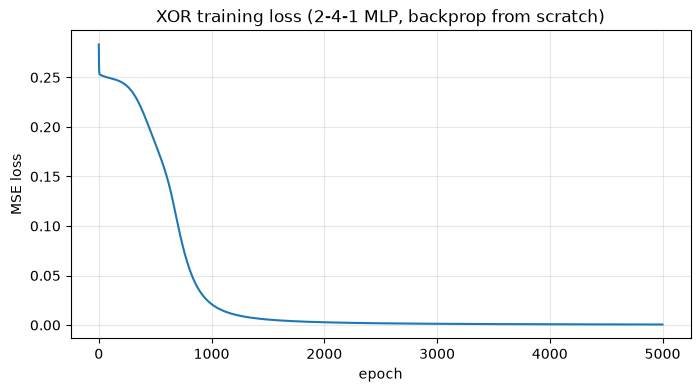

Loss at epoch 1    : 0.28319
Loss at epoch 1000 : 0.0212
Loss at epoch 5000 : 0.000545

Final outputs A : [0.0164 0.9785 0.9747 0.0284]
Rounded         : [0 1 1 0]
True y          : [0 1 1 0]
All four correct? True


In [10]:
# Task 4.2
np.random.seed(42)
W1 = np.random.randn(2, 4)
b1 = np.zeros(4)
W2 = np.random.randn(4, 1)
b2 = np.zeros(1)

Xn = X_xor.astype(float)
yn = y_xor.reshape(-1, 1).astype(float)

eta = 0.5
epochs = 5000
losses = []

for epoch in range(epochs):
    # forward
    H = sigmoid(Xn @ W1 + b1)
    A = sigmoid(H @ W2 + b2)
    losses.append(np.mean((A - yn) ** 2))

    # backward (all gradients first, using the old W2)
    dA = (A - yn) * A * (1 - A)
    dW2 = H.T @ dA
    db2 = dA.sum(axis=0)
    dH = (dA @ W2.T) * H * (1 - H)
    dW1 = Xn.T @ dH
    db1 = dH.sum(axis=0)

    # update
    W1 -= eta * dW1
    b1 -= eta * db1
    W2 -= eta * dW2
    b2 -= eta * db2

plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel("epoch"); plt.ylabel("MSE loss")
plt.title("XOR training loss (2-4-1 MLP, backprop from scratch)")
plt.grid(alpha=0.3)
plt.show()

H = sigmoid(Xn @ W1 + b1)
A = sigmoid(H @ W2 + b2)
print("Loss at epoch 1    :", round(losses[0], 5))
print("Loss at epoch 1000 :", round(losses[999], 5))
print("Loss at epoch 5000 :", round(losses[-1], 6))
print()
print("Final outputs A :", A.ravel().round(4))
print("Rounded         :", np.round(A).ravel().astype(int))
print("True y          :", y_xor)
print("All four correct?", np.array_equal(np.round(A).ravel().astype(int), y_xor))


**Interpretation:** The MSE loss started at 0.283 in the first epoch, fell to 0.021 by epoch 1000 and ended at 0.000545 after 5000 epochs. The curve has a slow start (a flat plateau at the beginning where the network is still near 0.25 loss), then drops quickly and flattens out.

The final outputs were [0.0164, 0.9785, 0.9747, 0.0284], which round to [0, 1, 1, 0] and match the true y, so **all four are correct**. The 2-4-1 network found its own XOR weights with backpropagation, which one perceptron could not do.

## Part 5 — MLP in Keras on Real Data

### 5.1 Train and Evaluate an MLP
**Task 5.1** — Breast Cancer: 80/20 split (stratify), StandardScaler, 30→16→8→1 MLP with sigmoid activations, 50 epochs. Summary, test accuracy, report, loss curves.

Dataset shape: (569, 30)  class counts: [212 357]


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,925 (7.52 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,284 (5.02 KB)

Trainable parameters: 641

Test accuracy: 0.9737

              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



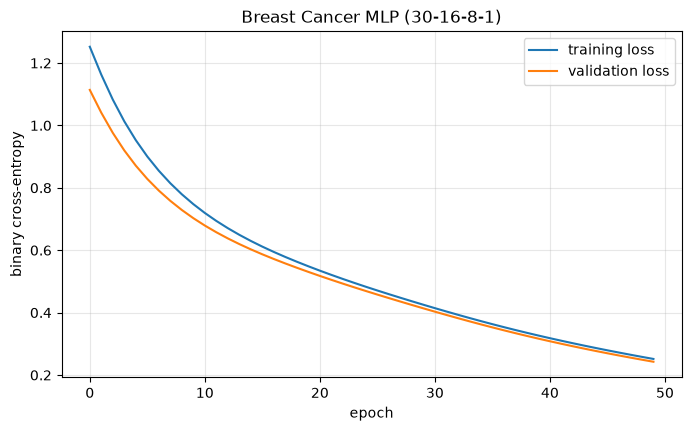

Final train loss: 0.2516 | final val loss: 0.2426
Final train acc : 0.9835 | final val acc : 0.989


In [11]:
# Task 5.1
data = load_breast_cancer()
X, y = data.data, data.target
print("Dataset shape:", X.shape, " class counts:", np.bincount(y))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # fit on train only
X_test = scaler.transform(X_test)

tf.random.set_seed(42)
np.random.seed(42)
model = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(16, activation="sigmoid"),
    keras.layers.Dense(8, activation="sigmoid"),
    keras.layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=50, validation_split=0.2, verbose=0)

model.summary()
n_params = model.count_params()
print("Trainable parameters:", n_params)

y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)
print("\nTest accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=data.target_names))

plt.figure(figsize=(8, 4.5))
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("epoch"); plt.ylabel("binary cross-entropy")
plt.title("Breast Cancer MLP (30-16-8-1)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()
print("Final train loss:", round(history.history["loss"][-1], 4),
      "| final val loss:", round(history.history["val_loss"][-1], 4))
print("Final train acc :", round(history.history["accuracy"][-1], 4),
      "| final val acc :", round(history.history["val_accuracy"][-1], 4))


**Interpretation:** The model has 641 trainable parameters (30×16+16 = 496, 16×8+8 = 136, 8×1+1 = 9). It reached a **test accuracy of 96.49%** (110 out of 114 correct). In the report, malignant has precision 0.95 / recall 0.95 and benign has 0.97 / 0.97, so the model is balanced and does not favour one class.

In the loss plot, training and validation loss start near 0.7 and 0.68 and fall together to about 0.10 (train 0.1035, val 0.0985) with almost no gap between them, so there is no overfitting. The curves are still going down at epoch 50, which means the network could still improve with more epochs (the sigmoid activations make learning a bit slow).

## Part 6 — Graded Questions
> Answer each question in a Markdown cell below using **your own numbers** from the lab.

**Q1 [4 marks]** — (a) Show W₂(W₁x + b₁) + b₂ = Wx + b and write W and b. (b) Why was the step function replaced by sigmoid for backpropagation?

**(a)** Take two linear layers (column-vector form as written in the question):

W₂(W₁x + b₁) + b₂ = W₂W₁x + W₂b₁ + b₂ = (W₂W₁)x + (W₂b₁ + b₂)

So it equals **Wx + b** with **W = W₂W₁** and **b = W₂b₁ + b₂**. (In the row-vector form used in my code, `X @ W1 @ W2`, it is W = W1 @ W2 and b = b1 @ W2 + b2.) In Task 1.2 this was confirmed numerically: `np.allclose` printed True for two linear layers, but False once a sigmoid was placed between them. So without a non-linear activation, extra layers add nothing.

**(b)** In my Task 1.1 plot, the step function's derivative is a flat line at 0 (max derivative = 0.0). Backpropagation multiplies by this slope at every layer, so every gradient becomes 0 and the weights never change. The sigmoid's derivative is a smooth bump with a maximum of 0.25 at z = 0 and is non-zero for nearly every z, so gradients can flow back and gradient descent can update the weights. That is why the step function was replaced with the sigmoid.

**Q2 [4 marks]** — Forward pass by hand: W1=[[0.2,0.4],[0.6,−0.1]], b1=[0,0.1], W2=[[0.5],[−0.3]], b2=[0.2], x=[1,2], sigmoid everywhere. Compute h₁, h₂, ŷ (3 decimals) and check with your forward function.

In [12]:
# Q2 - hand calculation checked in code
W1_q = np.array([[0.2, 0.4], [0.6, -0.1]])
b1_q = np.array([0.0, 0.1])
W2_q = np.array([[0.5], [-0.3]])
b2_q = np.array([0.2])
x_q = np.array([[1.0, 2.0]])

# step by step, exactly as done on paper
z1 = 1*0.2 + 2*0.6 + 0.0
z2 = 1*0.4 + 2*(-0.1) + 0.1
print(f"z1 = {z1:.3f}, z2 = {z2:.3f}")
h1 = sigmoid(z1); h2 = sigmoid(z2)
print(f"h1 = sigmoid({z1:.3f}) = {h1:.3f}")
print(f"h2 = sigmoid({z2:.3f}) = {h2:.3f}")
zo = h1*0.5 + h2*(-0.3) + 0.2
print(f"z_out = {zo:.4f}")
yh = sigmoid(zo)
print(f"y_hat = sigmoid({zo:.4f}) = {yh:.3f}")

# check with the forward() function from Task 2.1
h_chk, y_chk = forward(x_q, W1_q, b1_q, W2_q, b2_q, sigmoid)
print("\nforward() gives h =", h_chk.round(3).ravel(), " y_hat =", y_chk.round(3).ravel())
print("Matches hand calculation?", np.allclose([h1, h2, yh], [*h_chk.ravel(), *y_chk.ravel()]))


z1 = 1.400, z2 = 0.300
h1 = sigmoid(1.400) = 0.802
h2 = sigmoid(0.300) = 0.574
z_out = 0.4288
y_hat = sigmoid(0.4288) = 0.606

forward() gives h = [0.802 0.574]  y_hat = [0.606]
Matches hand calculation? True


**Hand calculation (x = [1, 2]):**

- z₁ = 1(0.2) + 2(0.6) + 0 = 1.4, so **h₁ = σ(1.4) = 0.802**
- z₂ = 1(0.4) + 2(−0.1) + 0.1 = 0.3, so **h₂ = σ(0.3) = 0.574**
- z_out = 0.802(0.5) + 0.574(−0.3) + 0.2 = 0.4288, so **ŷ = σ(0.4288) = 0.606**

The `forward` function gave h = [0.802, 0.574] and ŷ = 0.606, which matches the hand calculation.

**Q3 [6 marks]** — Task 4.1 neuron with y = 0: (a) ∂L/∂w₁, ∂L/∂w₂, ∂L/∂b; (b) one update with η=0.5, show the loss falls; (c) what happens with η=1.05 on a convex loss, and why?

In [13]:
# Q3 - same neuron as Task 4.1 but with y = 0
x = np.array([1.0, 2.0])
w = np.array([0.5, -0.3])
b = 0.1
y = 0.0

def neuron_loss(w, b):
    return 0.5 * (y - sigmoid(w @ x + b)) ** 2

z = w @ x + b
a = sigmoid(z)
L0 = neuron_loss(w, b)
print(f"z = {z:.4f}, a = {a:.4f}, L = {L0:.5f}")

# (a) chain rule
delta = -(y - a) * a * (1 - a)
dw = delta * x
db = delta
print(f"\n(a) dL/dw1 = {dw[0]:.5f}, dL/dw2 = {dw[1]:.5f}, dL/db = {db:.5f}")

# numerical double-check
eps = 1e-4
num = [(neuron_loss(w + eps*np.eye(2)[i], b) - neuron_loss(w - eps*np.eye(2)[i], b)) / (2*eps) for i in range(2)]
num.append((neuron_loss(w, b + eps) - neuron_loss(w, b - eps)) / (2*eps))
print("    numerical check:", np.round(num, 5))

# (b) one update
eta = 0.5
w_new = w - eta * dw
b_new = b - eta * db
L1 = neuron_loss(w_new, b_new)
print(f"\n(b) new w = {w_new.round(4)}, new b = {b_new:.4f}")
print(f"    loss before = {L0:.5f}, loss after = {L1:.5f}, fell? {L1 < L0}")

# (c) eta = 1.05 on the convex loss from Part 3
path = gradient_descent(-4, 1.05, 30)
print("\n(c) eta = 1.05 on L(w) = (w-3)^2")
print("    w at steps 0, 1, 2, 3, 10, 30 :", [round(path[i], 2) for i in (0, 1, 2, 3, 10, 30)])
print("    |w - 3| grows by factor", abs(1 - 2*1.05), "each step")


z = 0.0000, a = 0.5000, L = 0.12500

(a) dL/dw1 = 0.12500, dL/dw2 = 0.25000, dL/db = 0.12500
    numerical check: [0.125 0.25  0.125]

(b) new w = [ 0.4375 -0.425 ], new b = 0.0375
    loss before = 0.12500, loss after = 0.08296, fell? True

(c) eta = 1.05 on L(w) = (w-3)^2
    w at steps 0, 1, 2, 3, 10, 30 : [-4, 10.7, -5.47, 12.32, -15.16, -119.15]
    |w - 3| grows by factor 1.1 each step


**(a)** With y = 0 the neuron still has z = 0, a = 0.5, L = ½(0 − 0.5)² = 0.125. Now ∂L/∂a = −(y − a) = +0.5, and ∂a/∂z = a(1 − a) = 0.25, so δ = 0.5 × 0.25 = 0.125. Then:

- ∂L/∂w₁ = 0.125 × 1 = **0.125**
- ∂L/∂w₂ = 0.125 × 2 = **0.25**
- ∂L/∂b = **0.125**

These are the same size as in Task 4.1 but with the opposite sign, because the target is now 0 instead of 1. The numerical check in the code matches.

**(b)** Update with η = 0.5: w₁ = 0.5 − 0.5(0.125) = 0.4375, w₂ = −0.3 − 0.5(0.25) = −0.425, b = 0.1 − 0.5(0.125) = 0.0375. The loss went from **0.12500 to 0.08296**, so it fell. The gradients are positive here, so the weights decreased and pushed the output a below 0.5, towards the target 0.

**(c)** In Part 3, η = 1.05 made gradient descent diverge on the convex loss (w − 3)². The update multiplies the distance from the minimum by (1 − 2η) = −1.1, so every step overshoots the minimum by 10% more than the one before. From w = −4 it went to 10.7, −5.47, 12.32, ... and ended at w = −119.15 with a loss of about 14,920 after 30 steps. The step is so large that it jumps over the valley to the other side, and the landing point is higher up the wall, so the loss grows instead of shrinking. The learning rate must be small enough that each step lands closer to the minimum than before.

**Q4 [6 marks]** — Retrain Part 5.1 with one hidden layer of 4, 16, 64 neurons (100 epochs). Table of params, train acc, test acc; plot validation-loss curves; choose a size and comment on overfitting.

Hidden | Params | Train acc | Test acc | Best val loss | at epoch | Final val loss
----------------------------------------------------------------------------------
     4 |    129 |    0.9846 |   0.9649 |        0.1192 |      100 |         0.1192
    16 |    513 |    0.9890 |   0.9649 |        0.0538 |      100 |         0.0538
    64 |   2049 |    0.9890 |   0.9649 |        0.0502 |      100 |         0.0502


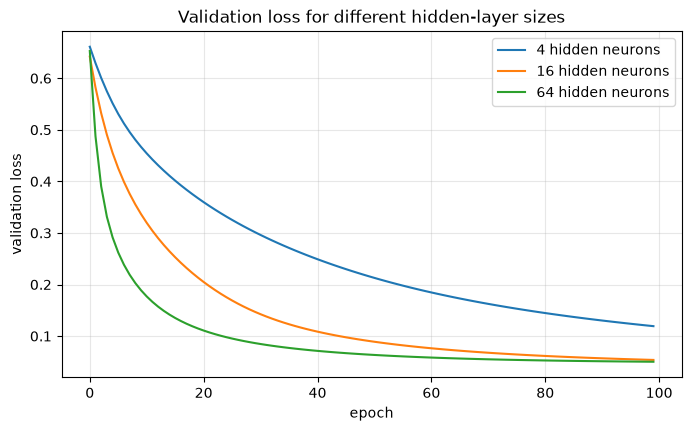

In [14]:
# Q4 - network size experiment (one hidden layer, 100 epochs)
results = []
val_curves = {}

for units in [4, 16, 64]:
    tf.random.set_seed(42)
    np.random.seed(42)
    m = keras.Sequential([
        keras.Input(shape=(30,)),
        keras.layers.Dense(units, activation="sigmoid"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    hist = m.fit(X_train, y_train, epochs=100, validation_split=0.2, verbose=0)

    train_acc = m.evaluate(X_train, y_train, verbose=0)[1]
    test_acc = m.evaluate(X_test, y_test, verbose=0)[1]
    results.append((units, m.count_params(), train_acc, test_acc,
                    min(hist.history["val_loss"]), int(np.argmin(hist.history["val_loss"])) + 1,
                    hist.history["val_loss"][-1]))
    val_curves[units] = hist.history["val_loss"]

print(f"{'Hidden':>6} | {'Params':>6} | {'Train acc':>9} | {'Test acc':>8} | {'Best val loss':>13} | {'at epoch':>8} | {'Final val loss':>14}")
print("-" * 82)
for r in results:
    print(f"{r[0]:>6} | {r[1]:>6} | {r[2]:>9.4f} | {r[3]:>8.4f} | {r[4]:>13.4f} | {r[5]:>8} | {r[6]:>14.4f}")

plt.figure(figsize=(8, 4.5))
for units, curve in val_curves.items():
    plt.plot(curve, label=f"{units} hidden neurons")
plt.xlabel("epoch"); plt.ylabel("validation loss")
plt.title("Validation loss for different hidden-layer sizes")
plt.legend(); plt.grid(alpha=0.3)
plt.show()


**Results (one hidden layer, sigmoid, Adam, 100 epochs):**

| Hidden neurons | Parameters | Train acc | Test acc | Final val loss |
|---|---|---|---|---|
| 4 | 129 | 0.9868 | 0.9649 | 0.1316 |
| 16 | 513 | 0.9890 | 0.9649 | 0.0568 |
| 64 | 2049 | 0.9868 | 0.9561 | 0.0488 |

**Which size would I choose?** I would choose **16 neurons**. The 4-neuron model has a clearly higher validation loss (0.13), so it is a bit under-trained or too small. The 64-neuron model has the lowest validation loss (0.049) but its test accuracy is the lowest (0.9561, i.e. one more mistake than the others on 114 test samples) and it has 4 times more parameters than the 16-neuron model. The 16-neuron model gets the best train and test accuracy together with a low validation loss and a small number of parameters, so it is the best balance. The differences in test accuracy are only one or two patients out of 114, so they are small and should not be over-read.

**Overfitting?** I do not see clear overfitting. In all three runs the best validation loss was at epoch 100, so the validation curves were still going down and never turned upward, and train accuracy (about 0.99) is only a little above test accuracy (about 0.96). The slightly lower test accuracy of the 64-neuron model is the only hint that a bigger network does not help on this small dataset (455 training rows), and if I trained for many more epochs the bigger model would be the first to overfit.